# Span Frames Analysis

Analysis of annotated spans mapped with FrameNet frames.


In [55]:
# Load data: Primary classification -> Span annotations -> Frames
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import ast

BASE = Path('/home/ashrafs/projects/Conspiracy-Proj')
DATA = BASE / 'Data'

# 1. Load primary classifications (conspiracy yes/no)
classifications = pd.read_csv(DATA / 'all_classifications.csv')
print(f'1. Classifications: {len(classifications)} rows')
print(f'   Columns: {list(classifications.columns[:10])}...')

# 2. Load span annotations (for conspiracy yes posts)
span_annotations = pd.read_csv(DATA / 'all_span_annotations.csv')
print(f'\n2. Span annotations: {len(span_annotations)} rows')
print(f'   Columns: {list(span_annotations.columns[:10])}...')

# 3. Load frames (extracted FrameNet frames for span elements)
frames_df = pd.read_csv(DATA / 'all_span_annotations_with_frames.csv')
print(f'\n3. Frames data: {len(frames_df)} rows')
print(f'   Columns: {len(frames_df.columns)} total')

# Identify key columns
SPAN_COLS = ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']
FRAME_COLS = [c for c in frames_df.columns if 'frame' in c.lower()]

print(f'\nSpan categories: {SPAN_COLS}')
print(f'Frame columns: {FRAME_COLS[:5]}... (showing first 5)')


1. Classifications: 3243 rows
   Columns: ['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy', 'supportive', 'misinformative']...

2. Span annotations: 934 rows
   Columns: ['annotator_id', 'text_id', 'annotation_id', 'text', 'out-group', 'plan', 'call-to-action', 'in-group', 'secret', 'This is a clear and direct expression of a classic anti-Semitic conspiracy theory. The deliberate poisoning of food and water by a specific Out-group which is jews. This plan is presented as a direct threat to the health and well-being of the implied In-group.']...

3. Frames data: 934 rows
   Columns: 58 total

Span categories: ['out-group', 'plan', 'call-to-action', 'in-group', 'secret']
Frame columns: ['The mention of "President Zelenskyy, the first of jewish origin of modern Ukraine" is included in a context that frames the rejection of a ceasefire negatively. This can be used as a dog whistle or "proof" for anti-Semitic conspiracy theories that portray Ukraine\'s government or the con

In [56]:
# Helper functions
def parse_frame_dict(val):
    """Parse frame dictionary: {frame_name: [lexical_units]}"""
    if pd.isna(val) or val == '' or str(val).lower() in ['nan', 'none', 'null']:
        return {}
    s = str(val).strip()
    if s == '' or s == '{}' or s == '[]':
        return {}
    try:
        parsed = ast.literal_eval(s)
        if isinstance(parsed, dict):
            result = {}
            for frame, units in parsed.items():
                if isinstance(units, list):
                    result[str(frame).strip()] = [str(u).strip() for u in units if u]
                elif isinstance(units, str):
                    result[str(frame).strip()] = [str(units).strip()]
                else:
                    result[str(frame).strip()] = [str(units).strip()] if units else []
            return result
        elif isinstance(parsed, list):
            return {str(f).strip(): [] for f in parsed if f}
        else:
            return {}
    except Exception:
        if ',' in s:
            frames = [f.strip() for f in s.split(',') if f.strip()]
            return {f: [] for f in frames}
        else:
            return {s: []} if s else {}

def is_present(col: pd.Series) -> pd.Series:
    """Check if span annotation is present"""
    s = col.astype(str).str.strip()
    sl = s.str.lower()
    return (
        col.notna() & 
        s.ne('') & 
        sl.ne('nan') & 
        sl.ne('none') & 
        sl.ne('null') & 
        sl.ne('[]')
    )

print('Helper functions defined.')


Helper functions defined.


In [58]:
# Join data: classifications -> span annotations -> frames
# Merge on annotation_id to align frames with span annotations

# Check available merge keys
print('Available merge keys:')
print(f'Classifications: {list(classifications.columns[:5])}...')
print(f'Span annotations: {list(span_annotations.columns[:5])}...')
print(f'Frames: {list(frames_df.columns[:5])}...')

# Find actual frame columns (should be at the end of the dataframe, like 'plan_frames', 'secret_frames')
# Frame columns are named: plan_frames, secret_frames, out-group_frames, in-group_frames, call-to-action_frames
actual_frame_cols = []
for col in frames_df.columns:
    col_lower = col.lower().strip()
    # Match columns that end with '_frames'
    if col_lower.endswith('_frames') and col not in ['annotation_id', 'annotator_id', 'text_id', 'text']:
        actual_frame_cols.append(col)
    
    # Also check for exact matches with span category names
    for span in SPAN_COLS:
        span_name = span.replace('-', '_')
        if col_lower == f'{span_name}_frames' or col_lower == f'{span}_frames':
            if col not in actual_frame_cols:
                actual_frame_cols.append(col)

print(f'\nActual frame columns found: {actual_frame_cols}')
print(f'\nAll columns in frames_df (last 10): {list(frames_df.columns[-10:])}')

# Show sample data from frame columns
if actual_frame_cols:
    print('\nSample frame column data:')
    for col in actual_frame_cols[:3]:  # Show first 3
        sample_val = frames_df[col].dropna().iloc[0] if (frames_df[col].dropna().shape[0] > 0) else None
        print(f'  {col}: {str(sample_val)[:100]}...' if sample_val else f'  {col}: (empty)')

# Merge span annotations with frames
if 'annotation_id' in span_annotations.columns and 'annotation_id' in frames_df.columns:
    # Get base columns from span_annotations
    base_cols = ['annotation_id', 'annotator_id', 'text_id', 'text'] + [c for c in SPAN_COLS if c in span_annotations.columns]
    
    # Get only frame columns from frames_df (plus annotation_id for merging)
    frame_cols_to_merge = ['annotation_id'] + actual_frame_cols
    
    # Merge: base span data + frame columns only
    merged = span_annotations[base_cols].merge(
        frames_df[frame_cols_to_merge],
        on='annotation_id',
        how='inner',
        suffixes=('', '_frames')
    )
    print(f'\nMerged span annotations + frames: {len(merged)} rows')
    print(f'Columns in merged: {len(merged.columns)} total')
    
    # Parse frame dictionaries for each actual frame column
    for col in actual_frame_cols:
        if col in merged.columns:
            merged[f'{col}_dict'] = merged[col].apply(parse_frame_dict)
    
    # Update FRAME_COLS to use actual frame columns
    FRAME_COLS = actual_frame_cols
    
    print('Frame dictionaries parsed.')
    print(f'\nFrame columns: {FRAME_COLS}')
    print(f'\nSample merged data:')
    display(merged[['annotation_id', 'text_id'] + SPAN_COLS[:2] + actual_frame_cols[:2] if actual_frame_cols else []].head())
else:
    print('Cannot merge: annotation_id not found in both dataframes')
    merged = None


Available merge keys:
Classifications: ['annotator_id', 'text_id', 'annotation_id', 'text', 'conspiracy']...
Span annotations: ['annotator_id', 'text_id', 'annotation_id', 'text', 'out-group']...
Frames: ['annotator_id', 'text_id', 'annotation_id', 'text', 'out-group']...

Actual frame columns found: ['plan_frames', 'secret_frames']

All columns in frames_df (last 10): ['France is the "in-group"', "I am sure there is something, I just can't detect it...", 'this could be the plan but it is stated as a fact', 'producers of ...', 'unfortunately, I cannot figure out how to add taxonomies.', 'They are implying madonna is sponsored by pfizer, but there is no plan,  nor in-group explicitely stated.', 'This could be the "secret plan" but it has been revealed, so it is not a secret anymore', 'This could be the pan but it is just a military prediction', 'plan_frames', 'secret_frames']

Sample frame column data:
  plan_frames: {'Performers_and_roles': {'be'}, 'Attempt_means': {'try'}, 'Try_defend

,annotation_id,text_id,out-group,plan,plan_frames,secret_frames
0,33463,21656,"Anti-White, Marxist hoardes",NaN,NaN,NaN
1,33368,21616,Oregon City Pride,the narrative they're trying to push,"{'Performers_and_roles': {'be'}, 'Attempt_mean...",NaN
2,33319,21595,American Anti-White politicians,ban TikTok,{'Prohibiting_or_licensing': {'ban'}},NaN
3,33494,21667,Muslim slave traders,anti-White revolts,"{'Color': {'white'}, 'Race_descriptor': {'whit...",NaN
4,33404,21631,normies,Genocide is underway for Japan,"{'Killing': {'genocide'}, 'Performers_and_role...",NaN


In [59]:
# Analysis 1: Frame extraction for span elements
# Extract frames for each span category (out-group, plan, call-to-action, in-group, secret)

if merged is not None and 'FRAME_COLS' in globals() and FRAME_COLS:
    # Map span columns to their frame columns
    # Frame columns are: plan_frames, secret_frames, out-group_frames, in-group_frames, call-to-action_frames
    span_frame_map = {}
    for span_col in SPAN_COLS:
        if span_col not in merged.columns:
            continue
        
        # Find corresponding frame column
        # Try: plan -> plan_frames, secret -> secret_frames, etc.
        frame_col = None
        span_name = span_col.replace('-', '_')
        
        # Try exact match: {span_name}_frames
        expected_names = [
            f'{span_name}_frames',  # plan -> plan_frames
            f'{span_col}_frames',   # call-to-action -> call-to-action_frames
        ]
        
        for name in expected_names:
            if name in FRAME_COLS:
                frame_col = name
                break
        
        # If not found, search for any frame column that matches
        if frame_col is None:
            for fc in FRAME_COLS:
                fc_lower = fc.lower().strip()
                # Match if frame column contains the span name
                if span_name in fc_lower and fc_lower.endswith('_frames'):
                    frame_col = fc
                    break
        
        if frame_col:
            span_frame_map[span_col] = frame_col
            print(f'  Mapped: {span_col} -> {frame_col}')
        else:
            print(f'  Warning: No frame column found for {span_col}')
    
    print('Span category -> Frame column mapping:')
    for span, frame_col in span_frame_map.items():
        print(f'  {span} -> {frame_col}')
    
    # Extract frames per span category
    frame_counts_by_span = {}
    frame_to_lexical_units = {}
    
    for span_col, frame_col in span_frame_map.items():
        # Get rows where this span is present
        present = is_present(merged[span_col])
        present_rows = merged[present]
        
        # Collect all frames for this span category
        frames = []
        frame_units_map = {}
        
        # Access the parsed dictionary column
        dict_col = f'{frame_col}_dict'
        if dict_col in present_rows.columns:
            for frame_dict in present_rows[dict_col]:
                if isinstance(frame_dict, dict):
                    for frame_name, lexical_units in frame_dict.items():
                        frames.append(frame_name)
                        if frame_name not in frame_units_map:
                            frame_units_map[frame_name] = []
                        frame_units_map[frame_name].extend(lexical_units)
        
        frame_counts_by_span[span_col] = Counter(frames)
        frame_to_lexical_units[span_col] = frame_units_map
    
    print('\nFrame counts by span category:')
    for span, counts in frame_counts_by_span.items():
        print(f'\n{span}:')
        print(f'  Total frame mentions: {sum(counts.values())}')
        print(f'  Unique frames: {len(counts)}')
        if counts:
            print(f'  Top 5 frames:')
            for frame, count in counts.most_common(5):
                units = frame_to_lexical_units.get(span, {}).get(frame, [])[:3]
                print(f'    {frame}: {count} mentions, sample lexical units: {units}')
else:
    print('Cannot analyze: merged data not available or no frame columns found')


  Mapped: plan -> plan_frames
  Mapped: secret -> secret_frames
Span category -> Frame column mapping:
  plan -> plan_frames
  secret -> secret_frames

Frame counts by span category:

plan:
  Total frame mentions: 13669
  Unique frames: 836
  Top 5 frames:
    Locative_relation: 319 mentions, sample lexical units: ["{'to'}", "{'to'}", "{'to'}"]
    Temporal_collocation: 294 mentions, sample lexical units: ["{'as'}", "{'in'}", "{'in'}"]
    Performers_and_roles: 280 mentions, sample lexical units: ["{'be'}", "{'be'}", "{'as'}"]
    Goal: 252 mentions, sample lexical units: ["{'to'}", "{'into'}", "{'to'}"]
    Origin: 250 mentions, sample lexical units: ["{'of'}", "{'of'}", "{'from'}"]

secret:
  Total frame mentions: 3196
  Unique frames: 582
  Top 5 frames:
    Performers_and_roles: 98 mentions, sample lexical units: ["{'be'}", "{'be'}", "{'be'}"]
    Locative_relation: 82 mentions, sample lexical units: ["{'over'}", "{'to'}", "{'to'}"]
    Origin: 78 mentions, sample lexical units: ["

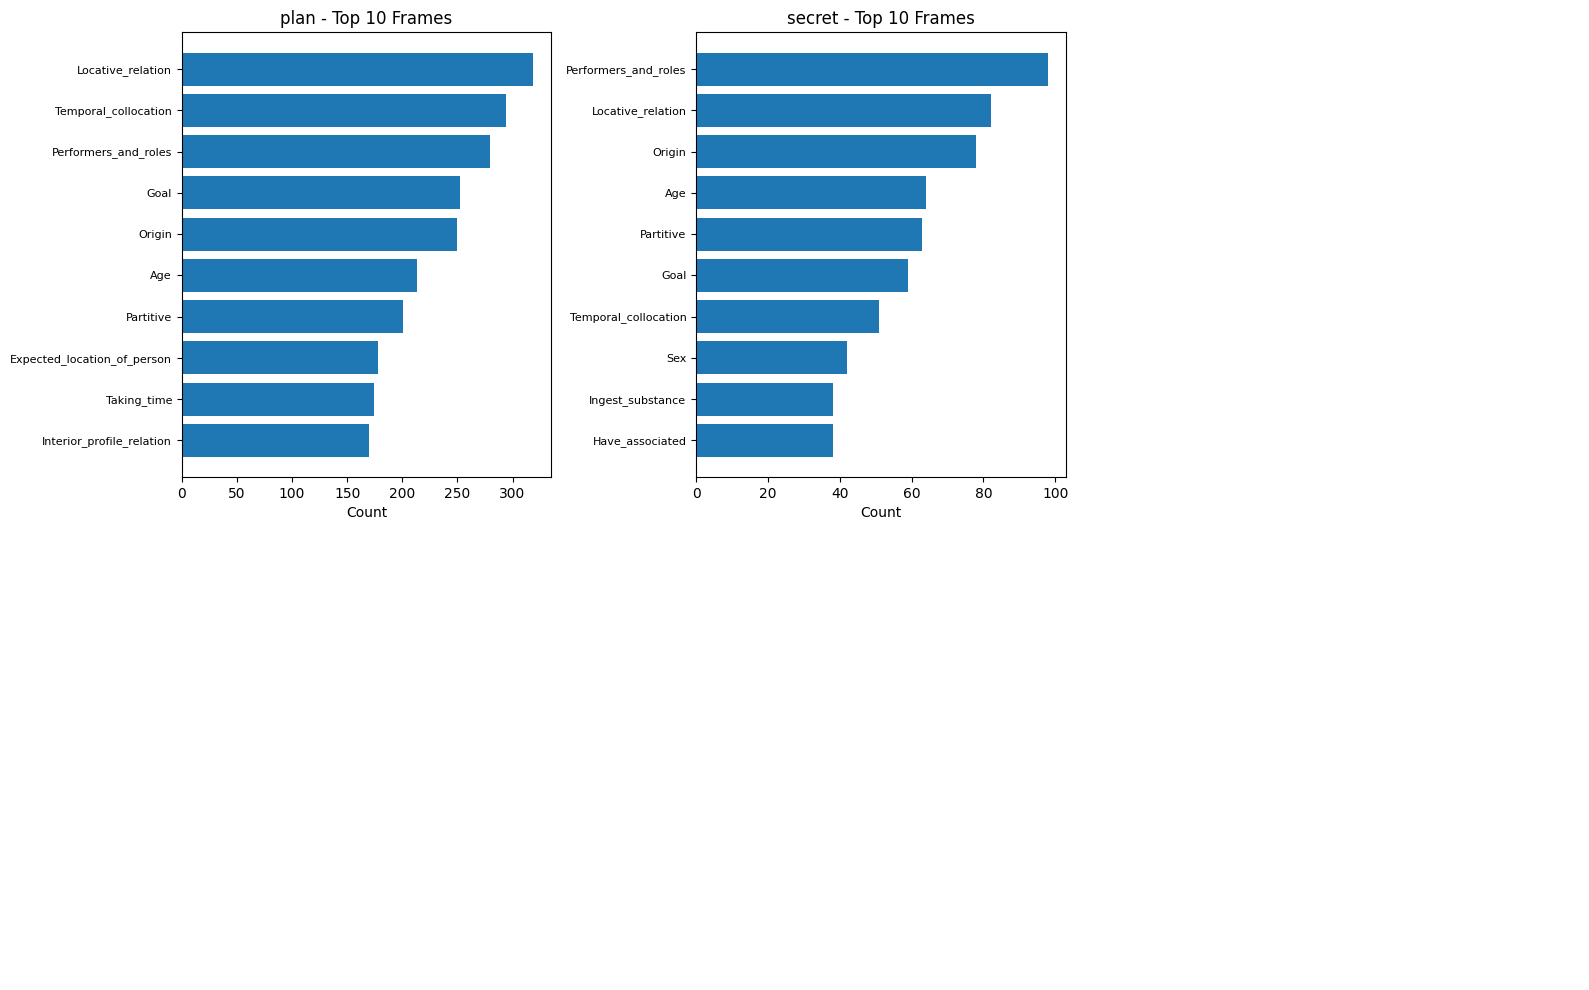

In [60]:
# Analysis 2: Visualize top frames per span category
if merged is not None and 'frame_counts_by_span' in globals():
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    
    for idx, (span, counts) in enumerate(frame_counts_by_span.items()):
        if idx >= len(axes):
            break
        ax = axes[idx]
        
        top_frames = counts.most_common(10)
        if not top_frames:
            ax.text(0.5, 0.5, 'No frames', ha='center', va='center')
            ax.set_title(f'{span}')
            continue
        
        frames, counts_list = zip(*top_frames)
        y_pos = np.arange(len(frames))
        
        ax.barh(y_pos, counts_list)
        ax.set_yticks(y_pos)
        ax.set_yticklabels([f[:30] for f in frames], fontsize=8)
        ax.set_xlabel('Count')
        ax.set_title(f'{span} - Top 10 Frames')
        ax.invert_yaxis()
    
    # Hide unused subplots
    for idx in range(len(frame_counts_by_span), len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print('Cannot visualize: frame data not available')


Total frame mentions: 16865
Unique frames: 855

Top 20 frames overall:
  Locative_relation: 401 mentions, sample lexical units: ["{'south'}", "{'meet'}", "{'to'}"]
  Performers_and_roles: 378 mentions, sample lexical units: ["{'star'}", "{'play'}", "{'role'}"]
  Temporal_collocation: 345 mentions, sample lexical units: ["{'today'}", "{'prehistoric'}", "{'on'}"]
  Origin: 328 mentions, sample lexical units: ["{'italian'}", "{'egyptian'}", "{'canadian'}"]
  Goal: 311 mentions, sample lexical units: ["{'into'}", "{'to'}"]
  Age: 277 mentions, sample lexical units: ["{'old'}", "{'new'}", "{'of'}"]
  Partitive: 264 mentions, sample lexical units: ["{'of'}"]
  Expected_location_of_person: 212 mentions, sample lexical units: ["{'home'}", "{'out'}", "{'in'}"]
  Taking_time: 204 mentions, sample lexical units: ["{'slow'}", "{'fast'}", "{'quick'}"]
  Interior_profile_relation: 203 mentions, sample lexical units: ["{'within'}", "{'inside'}", "{'amid'}"]
  Fields: 198 mentions, sample lexical unit

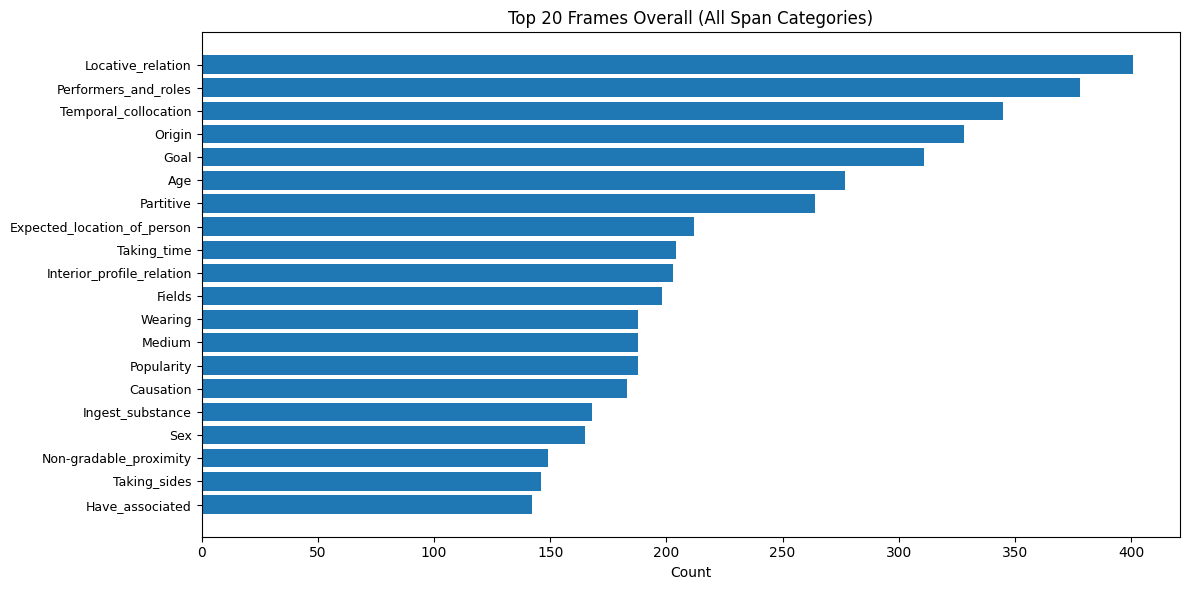

In [61]:
# Analysis 3: Overall frame frequency (across all span categories)
if merged is not None and 'frame_counts_by_span' in globals():
    # Aggregate all frames across all span categories
    all_frames = []
    overall_frame_to_units = {}
    
    for span, counts in frame_counts_by_span.items():
        for frame, count in counts.items():
            all_frames.extend([frame] * count)
            # Get lexical units for this frame
            if span in frame_to_lexical_units and frame in frame_to_lexical_units[span]:
                if frame not in overall_frame_to_units:
                    overall_frame_to_units[frame] = []
                overall_frame_to_units[frame].extend(frame_to_lexical_units[span][frame])
    
    overall_counts = Counter(all_frames)
    
    print(f'Total frame mentions: {sum(overall_counts.values())}')
    print(f'Unique frames: {len(overall_counts)}')
    print(f'\nTop 20 frames overall:')
    for frame, count in overall_counts.most_common(20):
        units_sample = list(set(overall_frame_to_units.get(frame, [])))[:3]
        print(f'  {frame}: {count} mentions, sample lexical units: {units_sample}')
    
    # Visualization
    top_20 = overall_counts.most_common(20)
    if top_20:
        frames, counts_list = zip(*top_20)
        plt.figure(figsize=(12, 6))
        y_pos = np.arange(len(frames))
        plt.barh(y_pos, counts_list)
        plt.yticks(y_pos, [f[:40] for f in frames], fontsize=9)
        plt.xlabel('Count')
        plt.title('Top 20 Frames Overall (All Span Categories)')
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()
else:
    print('Cannot analyze: frame data not available')


Top 20 co-occurring frame pairs:
  Goal + Locative_relation: 279
  Age + Origin: 243
  Origin + Partitive: 242
  Age + Partitive: 242
  Locative_relation + Temporal_collocation: 204
  Taking_time + Temporal_collocation: 185
  Interior_profile_relation + Temporal_collocation: 184
  Expected_location_of_person + Temporal_collocation: 184
  Fields + Temporal_collocation: 183
  Locative_relation + Performers_and_roles: 181
  Fields + Interior_profile_relation: 179
  Fields + Taking_time: 179
  Expected_location_of_person + Taking_time: 179
  Popularity + Temporal_collocation: 178
  Interior_profile_relation + Popularity: 178
  Popularity + Wearing: 178
  Medium + Popularity: 178
  Fields + Popularity: 178
  Popularity + Taking_time: 178
  Expected_location_of_person + Popularity: 178


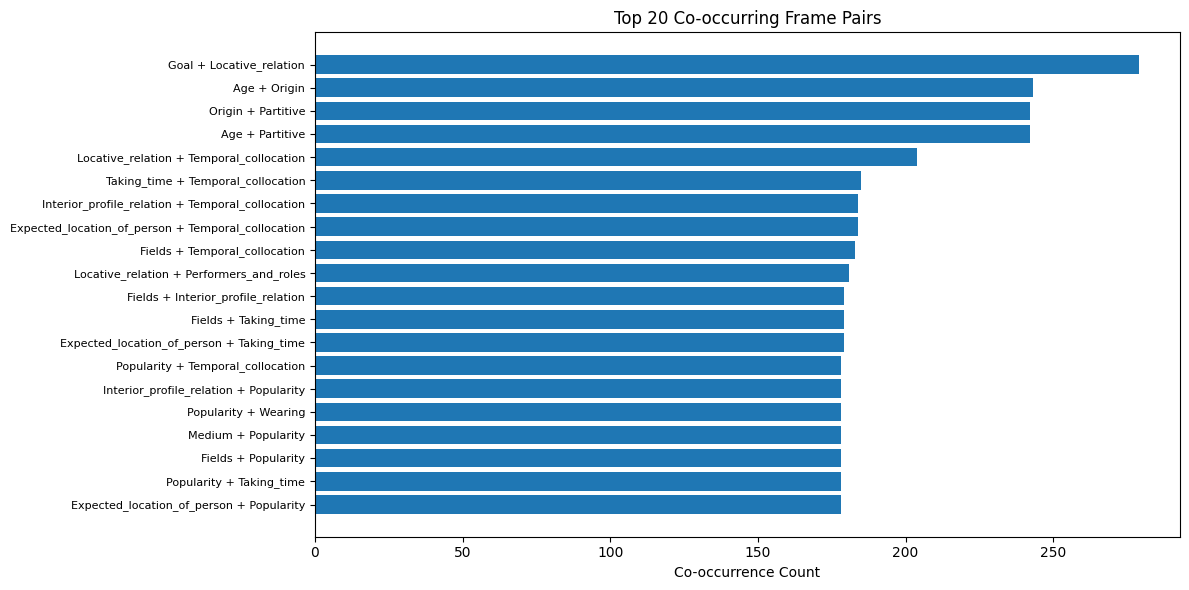

In [62]:
# Analysis 4: Frame co-occurrence analysis (which frames appear together)
if merged is not None and 'FRAME_COLS' in globals() and FRAME_COLS:
    cooccurrence = {}
    
    for idx, row in merged.iterrows():
        # Collect all frames for this annotation from all frame columns
        row_frames = []
        for col in FRAME_COLS:
            dict_col = f'{col}_dict'
            if dict_col in merged.columns:
                frame_dict = row[dict_col]
                if isinstance(frame_dict, dict):
                    row_frames.extend(frame_dict.keys())
        
        # Count co-occurrences
        unique_frames = list(set(row_frames))
        for i, f1 in enumerate(unique_frames):
            for f2 in unique_frames[i+1:]:
                pair = tuple(sorted([f1, f2]))
                cooccurrence[pair] = cooccurrence.get(pair, 0) + 1
    
    # Top co-occurring frame pairs
    top_pairs = sorted(cooccurrence.items(), key=lambda x: x[1], reverse=True)[:20]
    
    if top_pairs:
        print('Top 20 co-occurring frame pairs:')
        for (f1, f2), count in top_pairs:
            print(f'  {f1} + {f2}: {count}')
        
        # Visualization
        pairs_str = [f'{f1} + {f2}' for (f1, f2), _ in top_pairs]
        counts_list = [count for _, count in top_pairs]
        
        plt.figure(figsize=(12, 6))
        y_pos = np.arange(len(pairs_str))
        plt.barh(y_pos, counts_list)
        plt.yticks(y_pos, [p[:50] for p in pairs_str], fontsize=8)
        plt.xlabel('Co-occurrence Count')
        plt.title('Top 20 Co-occurring Frame Pairs')
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()
    else:
        print('No co-occurring frame pairs found.')
else:
    print('Cannot analyze: merged data or frame columns not available')


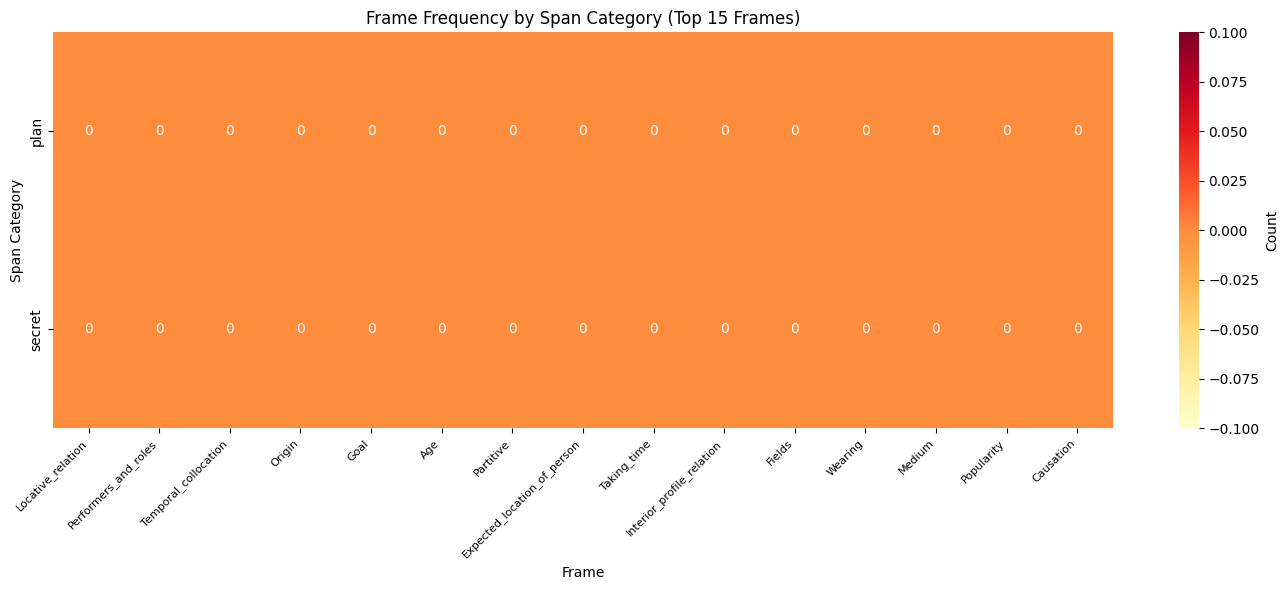

,Locative_relation,Performers_and_roles,Temporal_collocation,Origin,Goal,Age,Partitive,Expected_location_of_person,Taking_time,Interior_profile_relation,Fields,Wearing,Medium,Popularity,Causation
plan,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
secret,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [63]:
# Frame distribution by span category (heatmap)
# Get top frames across all categories
top_frames_all = [frame for frame, _ in overall_counts.most_common(15)]

# Build matrix: span_category x frame
matrix_data = []
for span in SPAN_COLS:
    if span not in frame_counts:
        continue
    row = []
    for frame in top_frames_all:
        count = frame_counts[span].get(frame, 0)
        row.append(count)
    matrix_data.append(row)

if matrix_data:
    span_labels = [s for s in SPAN_COLS if s in frame_counts]
    matrix_df = pd.DataFrame(matrix_data, index=span_labels, columns=top_frames_all)
    
    plt.figure(figsize=(14, 6))
    sns.heatmap(matrix_df, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Count'})
    plt.title('Frame Frequency by Span Category (Top 15 Frames)')
    plt.xlabel('Frame')
    plt.ylabel('Span Category')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.tight_layout()
    plt.show()
    
    display(matrix_df)


Summary Statistics:


,span_category,n_annotations,n_with_frames,pct_with_frames,unique_frames,total_frame_mentions
0,plan,786,1,0.127226,2,2
1,secret,283,0,0.000000,0,0


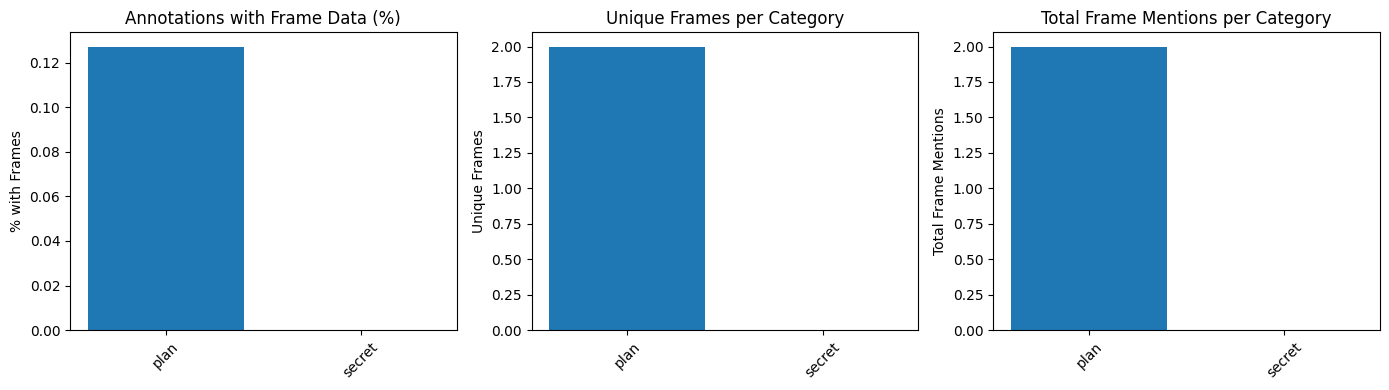

In [64]:
# Summary statistics
summary_stats = []

for span in SPAN_COLS:
    if span not in df.columns:
        continue
    present = is_present(df[span])
    n_annotations = present.sum()
    
    frame_col = span_frame_mapping.get(span)
    if frame_col:
        frames_with_data = df.loc[present, f'{frame_col}_parsed']
        frames_non_empty = [f for f in frames_with_data if isinstance(f, list) and len(f) > 0]
        n_with_frames = len(frames_non_empty)
        
        summary_stats.append({
            'span_category': span,
            'n_annotations': n_annotations,
            'n_with_frames': n_with_frames,
            'pct_with_frames': (n_with_frames / n_annotations * 100) if n_annotations > 0 else 0,
            'unique_frames': len(frame_counts.get(span, {})),
            'total_frame_mentions': sum(frame_counts.get(span, {}).values())
        })

summary_df = pd.DataFrame(summary_stats)
print('Summary Statistics:')
display(summary_df)

# Visualization
if not summary_df.empty:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    
    # Percentage with frames
    axes[0].bar(summary_df['span_category'], summary_df['pct_with_frames'])
    axes[0].set_ylabel('% with Frames')
    axes[0].set_title('Annotations with Frame Data (%)')
    axes[0].tick_params(axis='x', rotation=45)
    
    # Unique frames
    axes[1].bar(summary_df['span_category'], summary_df['unique_frames'])
    axes[1].set_ylabel('Unique Frames')
    axes[1].set_title('Unique Frames per Category')
    axes[1].tick_params(axis='x', rotation=45)
    
    # Total mentions
    axes[2].bar(summary_df['span_category'], summary_df['total_frame_mentions'])
    axes[2].set_ylabel('Total Frame Mentions')
    axes[2].set_title('Total Frame Mentions per Category')
    axes[2].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()


In [65]:
# Cache rebuild: ensure overall frame counts and frame->lexical units exist
from collections import Counter

if 'overall_frame_to_units' not in globals() or 'overall_counts' not in globals():
    overall_frame_to_units = {}
    all_frames = []
    all_lexical_units = []
    for col in FRAME_COLS:
        dict_col = f'{col}_dict'
        if dict_col not in df.columns:
            continue
        for frame_dict in df[dict_col]:
            if isinstance(frame_dict, dict):
                for frame, units in frame_dict.items():
                    all_frames.append(frame)
                    all_lexical_units.extend(units)
                    overall_frame_to_units.setdefault(frame, []).extend(units)
    overall_counts = Counter(all_frames)
    lexical_unit_counts_overall = Counter(all_lexical_units)

print(f'Cache ready: {len(overall_counts)} unique frames; {len(overall_frame_to_units)} frame entries')


Cache ready: 855 unique frames; 855 frame entries


Emerging frames (frequency <= 3): 247
Percentage of unique frames that are emerging: 28.9%

Top 30 emerging frames (by frequency):
  Indigenous_origin: 3 mentions, 2 unique lexical units
    Sample units: ["{'native'}", "{'native'}", "{'local'}"]
  Undergo_transformation: 3 mentions, 2 unique lexical units
    Sample units: ["{'transformation'}", "{'transformation'}", "{'transform'}"]
  Awareness_status: 3 mentions, 1 unique lexical units
    Sample units: ["{'possible'}", "{'possible'}", "{'possible'}"]
  Absorb_heat: 3 mentions, 1 unique lexical units
    Sample units: ["{'brown'}", "{'brown'}", "{'brown'}"]
  Apply_heat: 3 mentions, 1 unique lexical units
    Sample units: ["{'brown'}", "{'brown'}", "{'brown'}"]
  Notability: 3 mentions, 1 unique lexical units
    Sample units: ["{'great'}", "{'great'}", "{'great'}"]
  Violence: 3 mentions, 1 unique lexical units
    Sample units: ["{'violence'}", "{'violence'}", "{'violence'}"]
  Difficulty: 3 mentions, 3 unique lexical units
    S

,frame,frequency,unique_lexical_units,total_lexical_unit_mentions,sample_lexical_units
0,Indigenous_origin,3,2,3,"{'native'}, {'local'}"
1,Undergo_transformation,3,2,3,"{'transformation'}, {'transform'}"
2,Awareness_status,3,1,3,{'possible'}
3,Absorb_heat,3,1,3,{'brown'}
4,Apply_heat,3,1,3,{'brown'}
5,Notability,3,1,3,{'great'}
6,Violence,3,1,3,{'violence'}
7,Difficulty,3,3,3,"{'challenge'}, {'impossible'}, {'ease'}"
8,Attempt_suasion,3,2,3,"{'advocate'}, {'suggest'}"
9,Dominate_situation,3,1,3,{'rule'}



Common frames (frequency > 3): 608


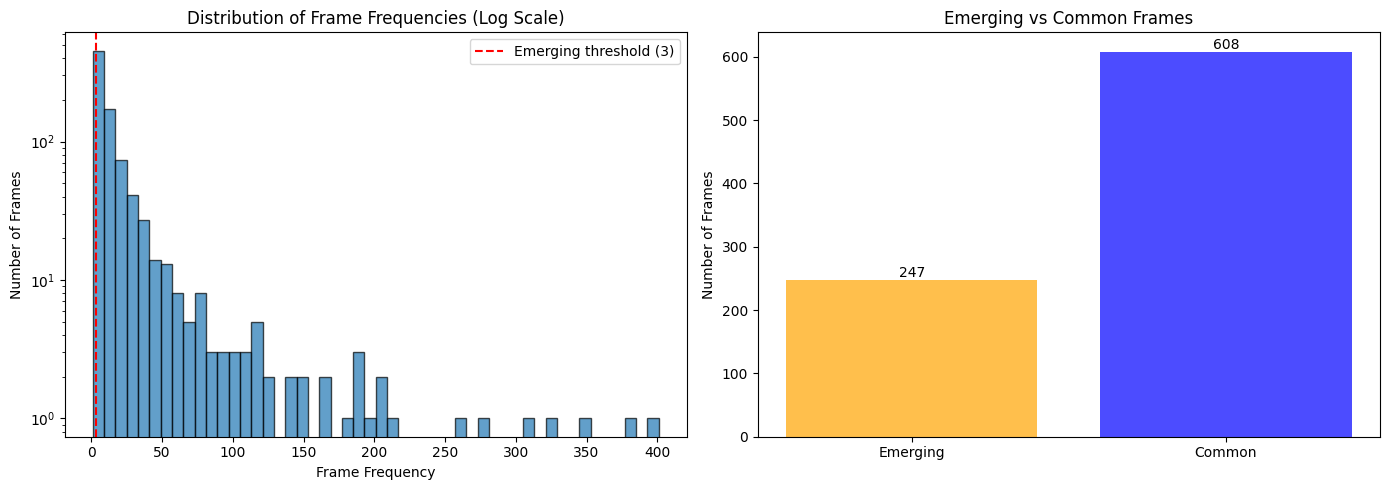


Emerging frames by span category:

plan: 2 emerging frames (out of 2 total)
  The Biden-Kamala regime chose to import these people en masse for a reason; this is a brazen "F*ck you: 1 mentions, 0 unique units, sample: []
  Whitey.": 1 mentions, 0 unique units, sample: []


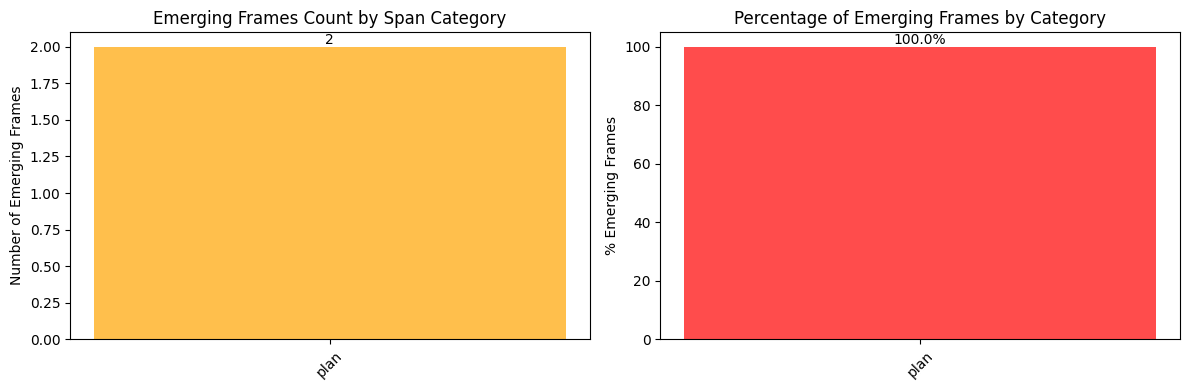

,span_category,n_emerging_frames,total_frames_in_category,pct_emerging
0,plan,2,2,100.0


In [66]:
# Analysis: Emerging frames (rare/novel frames)
# Define emerging frames as those with low frequency (e.g., <= 3 occurrences)
threshold = 3

emerging_frames = {frame: count for frame, count in overall_counts.items() if count <= threshold}
emerging_sorted = sorted(emerging_frames.items(), key=lambda x: x[1], reverse=True)

print(f'Emerging frames (frequency <= {threshold}): {len(emerging_frames)}')
print(f'Percentage of unique frames that are emerging: {len(emerging_frames)/len(overall_counts)*100:.1f}%')
print(f'\nTop 30 emerging frames (by frequency):')
for frame, count in emerging_sorted[:30]:
    units_sample = overall_frame_to_units.get(frame, [])[:5]
    unique_units = len(set(overall_frame_to_units.get(frame, [])))
    print(f'  {frame}: {count} mentions, {unique_units} unique lexical units')
    if units_sample:
        print(f'    Sample units: {units_sample}')

# Create summary DataFrame for emerging frames
emerging_data = []
for frame, count in emerging_sorted:
    units = overall_frame_to_units.get(frame, [])
    unique_units = list(set(units))
    emerging_data.append({
        'frame': frame,
        'frequency': count,
        'unique_lexical_units': len(unique_units),
        'total_lexical_unit_mentions': len(units),
        'sample_lexical_units': ', '.join(unique_units[:5])
    })

emerging_df = pd.DataFrame(emerging_data)
print('\nEmerging frames summary table:')
display(emerging_df.head(20))

# Visualization of emerging vs common frames
common_frames = {frame: count for frame, count in overall_counts.items() if count > threshold}
print(f'\nCommon frames (frequency > {threshold}): {len(common_frames)}')

# Distribution histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with log scale
counts_only = list(overall_counts.values())
axes[0].hist(counts_only, bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(threshold, color='red', linestyle='--', label=f'Emerging threshold ({threshold})')
axes[0].set_xlabel('Frame Frequency')
axes[0].set_ylabel('Number of Frames')
axes[0].set_title('Distribution of Frame Frequencies (Log Scale)')
axes[0].set_yscale('log')
axes[0].legend()

# Bar chart: Emerging vs Common
frame_types = ['Emerging', 'Common']
counts_by_type = [len(emerging_frames), len(common_frames)]
axes[1].bar(frame_types, counts_by_type, color=['orange', 'blue'], alpha=0.7)
axes[1].set_ylabel('Number of Frames')
axes[1].set_title('Emerging vs Common Frames')
for i, count in enumerate(counts_by_type):
    axes[1].text(i, count, str(count), ha='center', va='bottom')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Emerging frames by span category
print('\nEmerging frames by span category:')
span_emerging_summary = []
for span in SPAN_COLS:
    if span not in frame_counts:
        continue
    span_emerging = {f: c for f, c in frame_counts[span].items() if c <= threshold}
    if span_emerging:
        span_emerging_summary.append({
            'span_category': span,
            'n_emerging_frames': len(span_emerging),
            'total_frames_in_category': len(frame_counts[span]),
            'pct_emerging': len(span_emerging) / len(frame_counts[span]) * 100 if len(frame_counts[span]) > 0 else 0
        })
        print(f'\n{span}: {len(span_emerging)} emerging frames (out of {len(frame_counts[span])} total)')
        for frame, count in sorted(span_emerging.items(), key=lambda x: x[1], reverse=True)[:5]:
            units_sample = frame_to_lexical_units.get(span, {}).get(frame, [])[:3]
            unique_units = len(set(frame_to_lexical_units.get(span, {}).get(frame, [])))
            print(f'  {frame}: {count} mentions, {unique_units} unique units, sample: {units_sample}')

# Visualization of emerging frames by span category
if span_emerging_summary:
    span_df = pd.DataFrame(span_emerging_summary)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Count of emerging frames per category
    axes[0].bar(span_df['span_category'], span_df['n_emerging_frames'], color='orange', alpha=0.7)
    axes[0].set_ylabel('Number of Emerging Frames')
    axes[0].set_title('Emerging Frames Count by Span Category')
    axes[0].tick_params(axis='x', rotation=45)
    for i, count in enumerate(span_df['n_emerging_frames']):
        axes[0].text(i, count, str(count), ha='center', va='bottom')
    
    # Percentage of emerging frames per category
    axes[1].bar(span_df['span_category'], span_df['pct_emerging'], color='red', alpha=0.7)
    axes[1].set_ylabel('% Emerging Frames')
    axes[1].set_title('Percentage of Emerging Frames by Category')
    axes[1].tick_params(axis='x', rotation=45)
    for i, pct in enumerate(span_df['pct_emerging']):
        axes[1].text(i, pct, f'{pct:.1f}%', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()
    
    display(span_df)


In [67]:
# Analysis: Frame-to-lexical-unit relationships
# Identify frames with unique or distinctive lexical units
print('Frame-to-lexical-unit relationships:')
print(f'\nTotal unique frames: {len(overall_frame_to_units)}')

# Frames with most lexical units
frames_by_unit_count = sorted(
    [(frame, len(set(units))) for frame, units in overall_frame_to_units.items()],
    key=lambda x: x[1],
    reverse=True
)

print('\nTop 20 frames by unique lexical unit count:')
for frame, unit_count in frames_by_unit_count[:20]:
    total_mentions = overall_counts.get(frame, 0)
    unique_units = list(set(overall_frame_to_units.get(frame, [])))[:5]
    print(f'  {frame}: {unit_count} unique units, {total_mentions} mentions')
    print(f'    Sample units: {unique_units}')

# Frames with distinctive lexical units (only appear with that frame)
frame_exclusive_units = {}
for frame, units in overall_frame_to_units.items():
    unique_units = set(units)
    # Check if these units appear with other frames
    exclusive = []
    for unit in unique_units:
        appears_elsewhere = False
        for other_frame, other_units in overall_frame_to_units.items():
            if other_frame != frame and unit in other_units:
                appears_elsewhere = True
                break
        if not appears_elsewhere:
            exclusive.append(unit)
    if exclusive:
        frame_exclusive_units[frame] = exclusive

print(f'\nFrames with exclusive lexical units: {len(frame_exclusive_units)}')
for frame, exclusive_units in list(frame_exclusive_units.items())[:10]:
    print(f'  {frame}: {len(exclusive_units)} exclusive units')
    print(f'    {exclusive_units[:5]}')


Frame-to-lexical-unit relationships:

Total unique frames: 855

Top 20 frames by unique lexical unit count:
  Statement: 24 unique units, 113 mentions
    Sample units: ["{'report'}", "{'challenge'}", "{'speak'}", "{'comment'}", "{'write'}"]
  Locale_by_use: 23 unique units, 65 mentions
    Sample units: ["{'court'}", "{'port'}", "{'garden'}", "{'green'}", "{'base'}"]
  Calendric_unit: 22 unique units, 73 mentions
    Sample units: ["{'today'}", "{'month'}", "{'June'}", "{'day'}", "{'July'}"]
  Temporal_collocation: 20 unique units, 345 mentions
    Sample units: ["{'today'}", "{'prehistoric'}", "{'on'}", "{'current'}", "{'over'}"]
  Self_motion: 20 unique units, 77 mentions
    Sample units: ["{'fly'}", "{'run'}", "{'make'}", "{'cruise'}", "{'trip'}"]
  Leadership: 19 unique units, 69 mentions
    Sample units: ["{'administer'}", "{'administration'}", "{'run'}", "{'official'}", "{'rule'}"]
  Cause_motion: 18 unique units, 56 mentions
    Sample units: ["{'roll'}", "{'transfer'}", "{'a

Using span_frame_map:
  plan -> plan_frames
    plan: 786 rows with span present
    plan: extracted 13669 frame mentions
    plan: 836 unique frames
  secret -> secret_frames
    secret: 283 rows with span present
    secret: extracted 3196 frame mentions
    secret: 582 unique frames


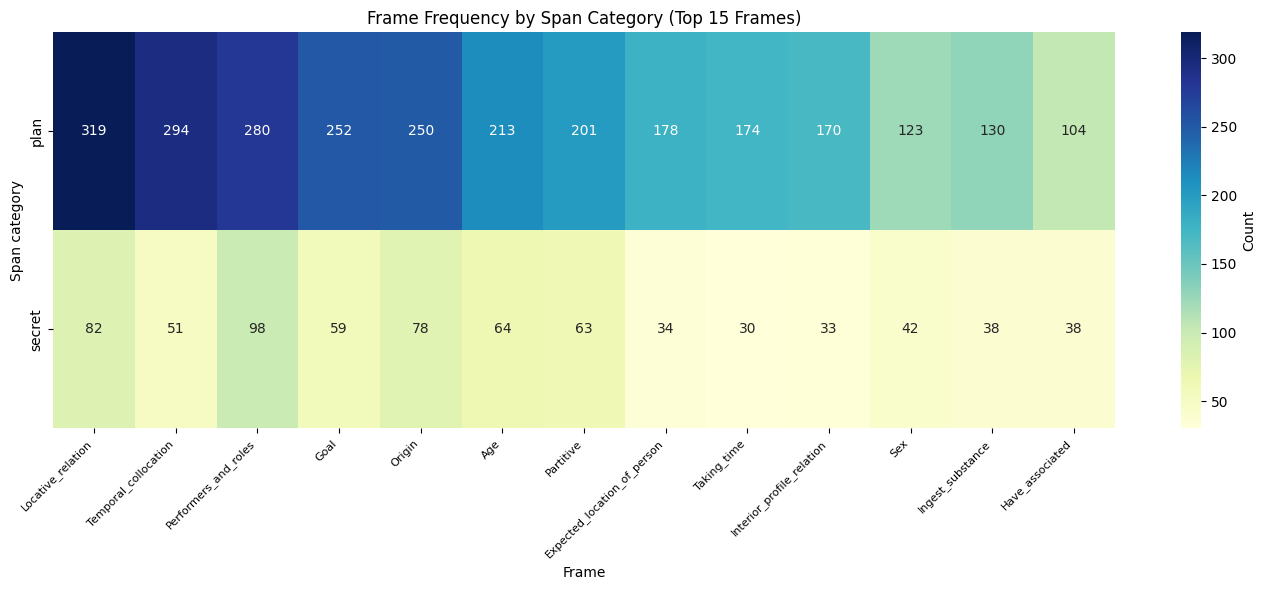

,Locative_relation,Temporal_collocation,Performers_and_roles,Goal,Origin,Age,Partitive,Expected_location_of_person,Taking_time,Interior_profile_relation,Sex,Ingest_substance,Have_associated
plan,319,294,280,252,250,213,201,178,174,170,123,130,104
secret,82,51,98,59,78,64,63,34,30,33,42,38,38


In [68]:
# Analysis 5: Frames for span elements (using already merged data)
# This analysis uses the merged data from cell 3 which already combines span annotations with frames

if merged is not None:
    # Use span_frame_map if available, otherwise use frame_counts_by_span from cell 4
    if 'span_frame_map' in globals() and span_frame_map:
        # Recompute frame counts using the proper span_frame_map
        frame_counts_base = {}
        print('Using span_frame_map:')
        for span_col, frame_col in span_frame_map.items():
            print(f'  {span_col} -> {frame_col}')
            if span_col not in merged.columns:
                print(f'    Skipping {span_col}: not in merged.columns')
                continue
            
            present = is_present(merged[span_col])
            n_present = present.sum()
            print(f'    {span_col}: {n_present} rows with span present')
            
            if n_present == 0:
                continue
            
            present_rows = merged[present]
            
            # Use the correct dict column
            dict_col = f'{frame_col}_dict'
            if dict_col not in present_rows.columns:
                print(f'    Skipping {span_col}: {dict_col} not in columns')
                print(f'    Available columns: {[c for c in present_rows.columns if "_dict" in c][:5]}...')
                continue
            
            frames = []
            for frame_dict in present_rows[dict_col]:
                if isinstance(frame_dict, dict) and frame_dict:
                    frames.extend(frame_dict.keys())
            
            print(f'    {span_col}: extracted {len(frames)} frame mentions')
            if frames:
                frame_counts_base[span_col] = Counter(frames)
                print(f'    {span_col}: {len(frame_counts_base[span_col])} unique frames')
    elif 'frame_counts_by_span' in globals() and frame_counts_by_span:
        # Fallback: use frame_counts_by_span from cell 4
        print('Using frame_counts_by_span from cell 4:')
        frame_counts_base = frame_counts_by_span
        for span, counts in frame_counts_base.items():
            print(f'  {span}: {len(counts)} unique frames, {sum(counts.values())} total mentions')
    else:
        print('Error: Neither span_frame_map nor frame_counts_by_span available.')
        print('Available globals:', [k for k in globals().keys() if 'frame' in k.lower() or 'span' in k.lower()][:10])
        frame_counts_base = {}
    
    # Build heatmap of top frames per category
    if frame_counts_base:
        top_frames_all = []
        for counts in frame_counts_base.values():
            for f, _ in counts.most_common(10):
                top_frames_all.append(f)
        
        # Unique frames, keep top by global frequency
        from collections import Counter as C
        if top_frames_all:
            global_top = [f for f, _ in C(top_frames_all).most_common(15)]
            mat = []
            row_labels = []
            for span in SPAN_COLS:
                if span not in frame_counts_base:
                    continue
                row_labels.append(span)
                row = [frame_counts_base[span].get(f, 0) for f in global_top]
                mat.append(row)
            
            if mat:
                mat_df = pd.DataFrame(mat, index=row_labels, columns=global_top)
                plt.figure(figsize=(14, 6))
                sns.heatmap(mat_df, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Count'})
                plt.title('Frame Frequency by Span Category (Top 15 Frames)')
                plt.ylabel('Span category')
                plt.xlabel('Frame')
                plt.xticks(rotation=45, ha='right', fontsize=8)
                plt.tight_layout()
                plt.show()
                display(mat_df)
            else:
                print('No matrix to plot.')
        else:
            print('No frames found in any category.')
    else:
        print('No frame counts computed. Check the debug output above.')
else:
    print('Cannot analyze: merged data not available. Run cell 3 first.')


Frame counts by span element:

PLAN:
  Unique frames: 836
  Total frame mentions: 13669
  Top 10 frames:
    Locative_relation: 319
    Temporal_collocation: 294
    Performers_and_roles: 280
    Goal: 252
    Origin: 250
    Age: 213
    Partitive: 201
    Expected_location_of_person: 178
    Taking_time: 174
    Interior_profile_relation: 170

CALL-TO-ACTION: No frames found

IN-GROUP: No frames found

OUT-GROUP: No frames found

SECRET:
  Unique frames: 582
  Total frame mentions: 3196
  Top 10 frames:
    Performers_and_roles: 98
    Locative_relation: 82
    Origin: 78
    Age: 64
    Partitive: 63
    Goal: 59
    Temporal_collocation: 51
    Sex: 42
    Ingest_substance: 38
    Have_associated: 38

Summary Table:


,span_element,unique_frames,total_frame_mentions,avg_mentions_per_frame
0,plan,836,13669,16.350478
1,call-to-action,0,0,0.000000
2,in-group,0,0,0.000000
3,out-group,0,0,0.000000
4,secret,582,3196,5.491409


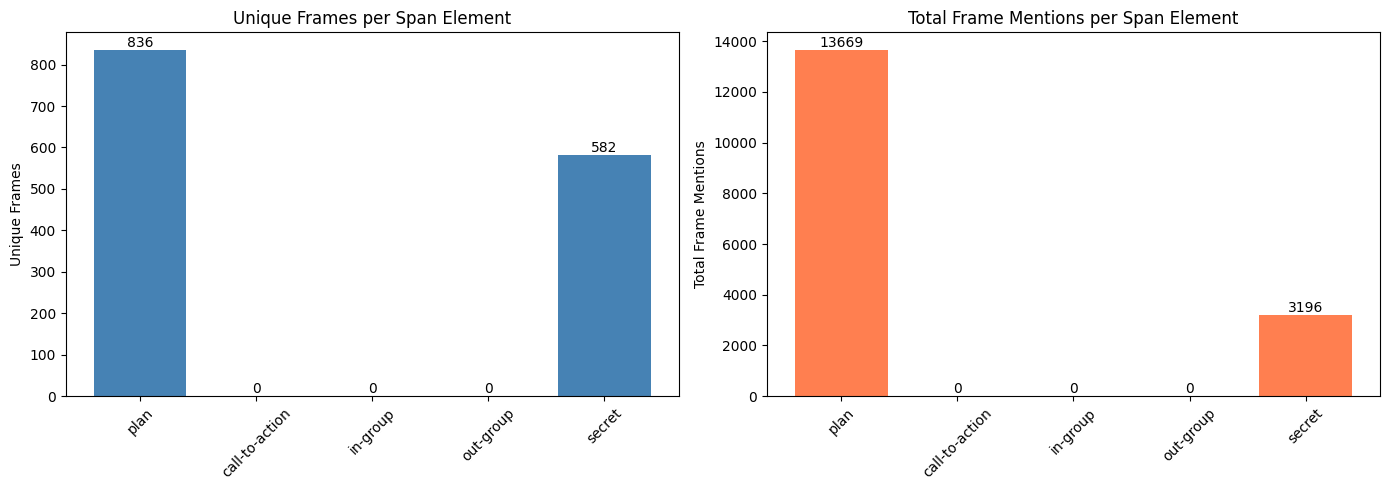

In [69]:
# Analysis 6: Frame counts for each span element/category
# Count frames for: 1. plan, 2. call-to-action, 3. in-group, 4. out-group, 5. secret

if merged is not None and 'frame_counts_by_span' in globals() and frame_counts_by_span:
    print('Frame counts by span element:')
    print('=' * 60)
    
    summary_data = []
    for span in ['plan', 'call-to-action', 'in-group', 'out-group', 'secret']:
        if span in frame_counts_by_span:
            counts = frame_counts_by_span[span]
            total_mentions = sum(counts.values())
            unique_frames = len(counts)
            
            summary_data.append({
                'span_element': span,
                'unique_frames': unique_frames,
                'total_frame_mentions': total_mentions,
                'avg_mentions_per_frame': total_mentions / unique_frames if unique_frames > 0 else 0
            })
            
            print(f'\n{span.upper()}:')
            print(f'  Unique frames: {unique_frames}')
            print(f'  Total frame mentions: {total_mentions}')
            if counts:
                print(f'  Top 10 frames:')
                for frame, count in counts.most_common(10):
                    print(f'    {frame}: {count}')
        else:
            print(f'\n{span.upper()}: No frames found')
            summary_data.append({
                'span_element': span,
                'unique_frames': 0,
                'total_frame_mentions': 0,
                'avg_mentions_per_frame': 0
            })
    
    # Summary table
    summary_df = pd.DataFrame(summary_data)
    print('\n' + '=' * 60)
    print('Summary Table:')
    display(summary_df)
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Unique frames per span element
    axes[0].bar(summary_df['span_element'], summary_df['unique_frames'], color='steelblue')
    axes[0].set_ylabel('Unique Frames')
    axes[0].set_title('Unique Frames per Span Element')
    axes[0].tick_params(axis='x', rotation=45)
    for i, val in enumerate(summary_df['unique_frames']):
        axes[0].text(i, val, str(val), ha='center', va='bottom')
    
    # Total frame mentions per span element
    axes[1].bar(summary_df['span_element'], summary_df['total_frame_mentions'], color='coral')
    axes[1].set_ylabel('Total Frame Mentions')
    axes[1].set_title('Total Frame Mentions per Span Element')
    axes[1].tick_params(axis='x', rotation=45)
    for i, val in enumerate(summary_df['total_frame_mentions']):
        axes[1].text(i, val, str(val), ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()
    
else:
    print('Cannot analyze: frame_counts_by_span not available. Run cell 4 first.')


Lexical units per frame:
Total unique frames: 855
Total unique lexical units (across all frames): 1386
Total lexical unit mentions: 16865

Top 20 frames by unique lexical units:
--------------------------------------------------------------------------------

Statement:
  Unique lexical units: 24
  Total mentions: 113
  Sample units: {'report'}, {'challenge'}, {'speak'}, {'comment'}, {'write'}, {'suggest'}, {'address'}, {'talk'}, {'...

Locale_by_use:
  Unique lexical units: 23
  Total mentions: 65
  Sample units: {'court'}, {'port'}, {'garden'}, {'green'}, {'base'}, {'facility'}, {'plantation'}, {'factory'}, {'p...

Calendric_unit:
  Unique lexical units: 22
  Total mentions: 73
  Sample units: {'today'}, {'month'}, {'June'}, {'day'}, {'July'}, {'August'}, {'Sunday'}, {'February'}, {'May'}, {'...

Temporal_collocation:
  Unique lexical units: 20
  Total mentions: 345
  Sample units: {'today'}, {'prehistoric'}, {'on'}, {'current'}, {'over'}, {'future'}, {'currently'}, {'early'}, {'a...

,frame,unique_lexical_units,total_lexical_unit_mentions,avg_mentions_per_unit,sample_lexical_units
142,Statement,24,113,4.708333,"{'report'}, {'challenge'}, {'speak'}, {'commen..."
244,Locale_by_use,23,65,2.826087,"{'court'}, {'port'}, {'garden'}, {'green'}, {'..."
168,Calendric_unit,22,73,3.318182,"{'today'}, {'month'}, {'June'}, {'day'}, {'Jul..."
35,Temporal_collocation,20,345,17.250000,"{'today'}, {'prehistoric'}, {'on'}, {'current'..."
125,Self_motion,20,77,3.850000,"{'fly'}, {'run'}, {'make'}, {'cruise'}, {'trip..."
83,Leadership,19,69,3.631579,"{'administer'}, {'administration'}, {'run'}, {..."
9,Cause_motion,18,56,3.111111,"{'roll'}, {'transfer'}, {'attract'}, {'pull'},..."
295,Placing,18,40,2.222222,"{'stuff'}, {'box'}, {'file'}, {'perch'}, {'sta..."
69,People_by_vocation,17,27,1.588235,"{'correspondent'}, {'politician'}, {'driver'},..."
7,Locative_relation,17,401,23.588235,"{'south'}, {'meet'}, {'to'}, {'where'}, {'at'}..."


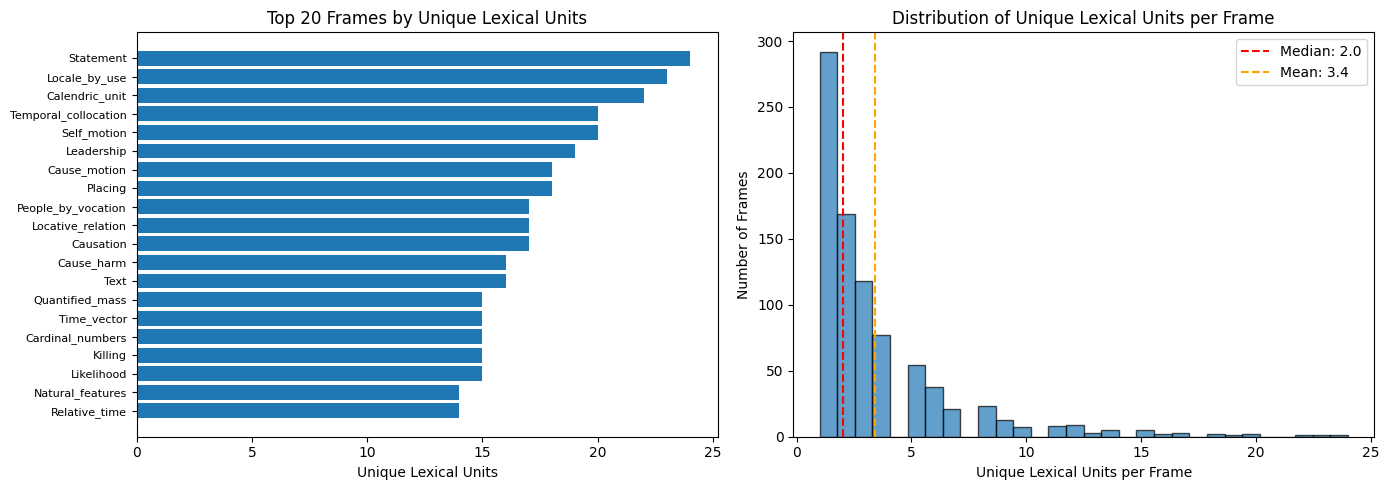


Lexical Unit Statistics:
Mean unique lexical units per frame: 3.43
Median unique lexical units per frame: 2.00
Max unique lexical units per frame: 24
Min unique lexical units per frame: 1


In [71]:
# Analysis 7: Lexical units per frame
# Count how many lexical units match each frame across all span elements

if merged is not None and 'frame_to_lexical_units' in globals() and frame_to_lexical_units:
    # Aggregate lexical units per frame across all span categories
    frame_lexical_units_all = {}
    
    for span, frame_units_map in frame_to_lexical_units.items():
        for frame, units in frame_units_map.items():
            if frame not in frame_lexical_units_all:
                frame_lexical_units_all[frame] = []
            frame_lexical_units_all[frame].extend(units)
    
    # Count unique and total lexical units per frame
    frame_lexical_stats = []
    for frame, units in frame_lexical_units_all.items():
        unique_units = list(set(units))
        total_mentions = len(units)
        unique_count = len(unique_units)
        
        frame_lexical_stats.append({
            'frame': frame,
            'unique_lexical_units': unique_count,
            'total_lexical_unit_mentions': total_mentions,
            'avg_mentions_per_unit': total_mentions / unique_count if unique_count > 0 else 0,
            'sample_lexical_units': ', '.join(unique_units[:10])
        })
    
    # Sort by unique lexical units count
    frame_lexical_df = pd.DataFrame(frame_lexical_stats).sort_values('unique_lexical_units', ascending=False)
    
    print('Lexical units per frame:')
    print('=' * 80)
    print(f'Total unique frames: {len(frame_lexical_df)}')
    print(f'Total unique lexical units (across all frames): {len(set([u for units in frame_lexical_units_all.values() for u in units]))}')
    print(f'Total lexical unit mentions: {sum([len(u) for u in frame_lexical_units_all.values()])}')
    
    print('\nTop 20 frames by unique lexical units:')
    print('-' * 80)
    for idx, row in frame_lexical_df.head(20).iterrows():
        print(f'\n{row["frame"]}:')
        print(f'  Unique lexical units: {row["unique_lexical_units"]}')
        print(f'  Total mentions: {row["total_lexical_unit_mentions"]}')
        print(f'  Sample units: {row["sample_lexical_units"][:100]}...')
    
    # Summary table
    print('\n' + '=' * 80)
    print('Summary Statistics:')
    display(frame_lexical_df.head(30))
    
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Top 20 frames by unique lexical units
    top_20 = frame_lexical_df.head(20)
    axes[0].barh(range(len(top_20)), top_20['unique_lexical_units'].values)
    axes[0].set_yticks(range(len(top_20)))
    axes[0].set_yticklabels([f[:30] for f in top_20['frame'].values], fontsize=8)
    axes[0].set_xlabel('Unique Lexical Units')
    axes[0].set_title('Top 20 Frames by Unique Lexical Units')
    axes[0].invert_yaxis()
    
    # Distribution of unique lexical units per frame
    axes[1].hist(frame_lexical_df['unique_lexical_units'], bins=30, edgecolor='black', alpha=0.7)
    axes[1].set_xlabel('Unique Lexical Units per Frame')
    axes[1].set_ylabel('Number of Frames')
    axes[1].set_title('Distribution of Unique Lexical Units per Frame')
    axes[1].axvline(frame_lexical_df['unique_lexical_units'].median(), color='red', linestyle='--', 
                    label=f'Median: {frame_lexical_df["unique_lexical_units"].median():.1f}')
    axes[1].axvline(frame_lexical_df['unique_lexical_units'].mean(), color='orange', linestyle='--', 
                    label=f'Mean: {frame_lexical_df["unique_lexical_units"].mean():.1f}')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Statistics
    print('\n' + '=' * 80)
    print('Lexical Unit Statistics:')
    print(f'Mean unique lexical units per frame: {frame_lexical_df["unique_lexical_units"].mean():.2f}')
    print(f'Median unique lexical units per frame: {frame_lexical_df["unique_lexical_units"].median():.2f}')
    print(f'Max unique lexical units per frame: {frame_lexical_df["unique_lexical_units"].max()}')
    print(f'Min unique lexical units per frame: {frame_lexical_df["unique_lexical_units"].min()}')
    
else:
    print('Cannot analyze: frame_to_lexical_units not available. Run cell 4 first.')


## Using Frames and Lexical Units for Span Annotation (Task 3)

This section shows how to use the extracted FrameNet frames and lexical units to enhance span annotation by models.


In [72]:
# Setup: Extract frames and lexical units as annotation guidance
# This creates a knowledge base that can be used in span annotation prompts

if merged is not None and 'frame_counts_by_span' in globals() and 'frame_to_lexical_units' in globals():
    # Build a knowledge base: for each span category, what frames and lexical units are common
    span_knowledge_base = {}
    
    for span in SPAN_COLS:
        if span not in frame_counts_by_span:
            continue
        
        # Get top frames for this span category
        top_frames = frame_counts_by_span[span].most_common(20)
        
        # For each frame, get its lexical units
        frame_lexical_guide = {}
        for frame, count in top_frames:
            units = frame_to_lexical_units.get(span, {}).get(frame, [])
            unique_units = list(set(units))
            if unique_units:
                frame_lexical_guide[frame] = {
                    'lexical_units': unique_units[:15],  # Top 15 unique units
                    'frequency': count,
                    'total_units': len(units),
                    'unique_units_count': len(unique_units)
                }
        
        span_knowledge_base[span] = {
            'top_frames': top_frames,
            'frame_lexical_units': frame_lexical_guide,
            'total_unique_frames': len(frame_counts_by_span[span])
        }
    
    print('Knowledge base created for span annotation guidance:')
    print('=' * 80)
    for span, kb in span_knowledge_base.items():
        print(f'\n{span.upper()}:')
        print(f'  Total unique frames: {kb["total_unique_frames"]}')
        print(f'  Top 5 frames with lexical units:')
        for frame, count in kb['top_frames'][:5]:
            if frame in kb['frame_lexical_units']:
                units = kb['frame_lexical_units'][frame]['lexical_units'][:5]
                print(f'    {frame} ({count} mentions): {units}')
    
    # Save as JSON for easy use in prompts
    import json
    knowledge_base_json = {}
    for span, kb in span_knowledge_base.items():
        knowledge_base_json[span] = {
            'frames': [
                {
                    'frame': frame,
                    'frequency': count,
                    'lexical_units': kb['frame_lexical_units'].get(frame, {}).get('lexical_units', [])
                }
                for frame, count in kb['top_frames'][:20]
            ]
        }
    
    print('\n' + '=' * 80)
    print('Knowledge base structure (for use in prompts):')
    print(json.dumps({k: {k2: len(v2) if isinstance(v2, list) else v2 for k2, v2 in v.items()} 
                     for k, v in knowledge_base_json.items()}, indent=2))
    
else:
    print('Cannot create knowledge base: Required data not available. Run cells 3 and 4 first.')


Knowledge base created for span annotation guidance:

PLAN:
  Total unique frames: 836
  Top 5 frames with lexical units:
    Locative_relation (319 mentions): ["{'south'}", "{'meet'}", "{'to'}", "{'where'}", "{'at'}"]
    Temporal_collocation (294 mentions): ["{'today'}", "{'on'}", "{'current'}", "{'over'}", "{'future'}"]
    Performers_and_roles (280 mentions): ["{'star'}", "{'play'}", "{'part'}", "{'appear'}", "{'act'}"]
    Goal (252 mentions): ["{'into'}", "{'to'}"]
    Origin (250 mentions): ["{'italian'}", "{'canadian'}", "{'european'}", "{'of'}", "{'american'}"]

SECRET:
  Total unique frames: 582
  Top 5 frames with lexical units:
    Performers_and_roles (98 mentions): ["{'as'}", "{'role'}", "{'be'}"]
    Locative_relation (82 mentions): ["{'to'}", "{'where'}", "{'at'}", "{'down'}", "{'out'}"]
    Origin (78 mentions): ["{'italian'}", "{'egyptian'}", "{'of'}", "{'american'}", "{'french'}"]
    Age (64 mentions): ["{'young'}", "{'of'}"]
    Partitive (63 mentions): ["{'of'}"]


In [73]:
# Example: Generate prompt template using frames and lexical units
# This shows how to incorporate frame knowledge into span annotation prompts

if 'span_knowledge_base' in globals() and span_knowledge_base:
    def generate_span_annotation_prompt(text, span_category, use_frames=True):
        """
        Generate a prompt for annotating a specific span category, optionally using frame guidance.
        """
        base_prompt = f"""Annotate the following text for the "{span_category}" span element.
        
Text: {text}

"""
        if use_frames and span_category in span_knowledge_base:
            kb = span_knowledge_base[span_category]
            frame_examples = []
            for frame, count in kb['top_frames'][:5]:
                if frame in kb['frame_lexical_units']:
                    units = kb['frame_lexical_units'][frame]['lexical_units'][:5]
                    frame_examples.append(f"- {frame}: look for words like {', '.join(units)}")
            
            frame_guidance = f"""
Guidance: Common FrameNet frames for "{span_category}" include:
{chr(10).join(frame_examples)}

When annotating, consider these frames and their associated lexical units.
"""
            return base_prompt + frame_guidance
        else:
            return base_prompt + "Extract the span element."
    
    # Example usage
    print('Example prompt generation:')
    print('=' * 80)
    sample_text = "The government is planning to replace the population through immigration."
    for span_cat in ['plan', 'out-group']:
        prompt = generate_span_annotation_prompt(sample_text, span_cat, use_frames=True)
        print(f'\n{span_cat.upper()} annotation prompt:')
        print('-' * 80)
        print(prompt)
        print()
    
    print('=' * 80)
    print('This prompt template can be used in LLM annotation scripts.')
else:
    print('Knowledge base not available. Run cell 17 first.')


Example prompt generation:

PLAN annotation prompt:
--------------------------------------------------------------------------------
Annotate the following text for the "plan" span element.
        
Text: The government is planning to replace the population through immigration.


Guidance: Common FrameNet frames for "plan" include:
- Locative_relation: look for words like {'south'}, {'meet'}, {'to'}, {'where'}, {'at'}
- Temporal_collocation: look for words like {'today'}, {'on'}, {'current'}, {'over'}, {'future'}
- Performers_and_roles: look for words like {'star'}, {'play'}, {'part'}, {'appear'}, {'act'}
- Goal: look for words like {'into'}, {'to'}
- Origin: look for words like {'italian'}, {'canadian'}, {'european'}, {'of'}, {'american'}

When annotating, consider these frames and their associated lexical units.



OUT-GROUP annotation prompt:
--------------------------------------------------------------------------------
Annotate the following text for the "out-group" span element.

In [74]:
# Export: Save knowledge base for use in annotation scripts
if 'span_knowledge_base' in globals() and span_knowledge_base:
    import json
    from pathlib import Path
    
    # Save as JSON
    output_path = BASE / 'Data' / 'span_frames_knowledge_base.json'
    with open(output_path, 'w') as f:
        json.dump(knowledge_base_json, f, indent=2)
    
    print(f'Knowledge base saved to: {output_path}')
    
    # Also save as a Python dictionary for direct import
    output_py = BASE / 'Data' / 'span_frames_knowledge_base.py'
    with open(output_py, 'w') as f:
        f.write('# Span frames knowledge base for annotation guidance\n')
        f.write('# Generated from FrameNet frame analysis\n\n')
        f.write(f'SPAN_FRAMES_KB = {repr(knowledge_base_json)}\n')
    
    print(f'Knowledge base saved as Python dict to: {output_py}')
    print('\nUsage in annotation scripts:')
    print('  from Data.span_frames_knowledge_base import SPAN_FRAMES_KB')
    print('  # Access: SPAN_FRAMES_KB["plan"]["frames"][0]["lexical_units"]')
else:
    print('Knowledge base not available. Run cell 17 first.')


Knowledge base saved to: /home/ashrafs/projects/Conspiracy-Proj/Data/span_frames_knowledge_base.json
Knowledge base saved as Python dict to: /home/ashrafs/projects/Conspiracy-Proj/Data/span_frames_knowledge_base.py

Usage in annotation scripts:
  from Data.span_frames_knowledge_base import SPAN_FRAMES_KB
  # Access: SPAN_FRAMES_KB["plan"]["frames"][0]["lexical_units"]


### How to Use Frames for Span Annotation:

**Option 1: Few-shot prompting with frame examples**
- Include top frames and their lexical units as examples in prompts
- Model learns to recognize patterns associated with each span category

**Option 2: Frame-guided validation**
- After model annotation, check if extracted spans match expected frames
- Use frames as validation criteria

**Option 3: Frame-aware annotation**
- Include frame information directly in the annotation task
- Model outputs both span and associated frame

**Option 4: Lexical unit matching**
- Use lexical units as keywords to identify potential spans
- Pre-filter text regions that contain frame-associated lexical units


In [ ]:
# Generate enhanced prompt with frame guidance
# This creates a prompt file that reuses few-shot examples + adds frame knowledge

if 'span_knowledge_base' in globals() and span_knowledge_base:
    # Build frame guidance section for each span category
    frame_guidance_sections = []
    
    span_label_mapping = {
        'plan': 'plan_event',
        'secret': 'secret',
        'out-group': 'out_group',
        'in-group': 'in_group',
        'call-to-action': 'call_to_action'
    }
    
    for span_cat, span_label in span_label_mapping.items():
        if span_cat in span_knowledge_base:
            kb = span_knowledge_base[span_cat]
            guidance = f"\n{span_label.upper()} ({span_cat}) Frame Guidance:\n"
            guidance += f"- Common FrameNet frames for {span_label} include:\n"
            
            # Add top 5 frames with their lexical units
            for frame, count in kb['top_frames'][:5]:
                if frame in kb['frame_lexical_units']:
                    units = kb['frame_lexical_units'][frame]['lexical_units'][:8]
                    guidance += f"  • {frame}: look for words/phrases like {', '.join(units[:5])}"
                    if len(units) > 5:
                        guidance += f", {', '.join(units[5:8])}"
                    guidance += "\n"
            
            frame_guidance_sections.append((span_label, guidance))
    
    # Read the original prompt
    original_prompt_path = BASE / 'Data' / 'prompts' / 'llama_few_shot_prompt.txt'
    with open(original_prompt_path, 'r') as f:
        original_prompt = f.read()
    
    # Create enhanced prompt by inserting frame guidance after span labels section
    frame_guidance_text = "\nFrameNet Frame Guidance (use these frames and lexical units to help identify spans):\n" + "".join([guidance for _, guidance in frame_guidance_sections])
    
    # Insert frame guidance after "Span text" section (before "Output JSON schema")
    insertion_point = "Span text should be a continuous substring from the input text.\n\n"
    enhanced_prompt = original_prompt.replace(
        insertion_point,
        insertion_point + frame_guidance_text + "\n"
    )
    
    # Save enhanced prompt
    output_path = BASE / 'Data' / 'prompts' / 'llama_few_shot_prompt_with_frames.txt'
    with open(output_path, 'w') as f:
        f.write(enhanced_prompt)
    
    print(f'Enhanced prompt saved to: {output_path}')
    print('\nFrame guidance added for:')
    for span_label, _ in frame_guidance_sections:
        print(f'  - {span_label}')
    
    # Show preview
    print('\n' + '=' * 80)
    print('Preview of enhanced prompt (Frame Guidance section):')
    print('=' * 80)
    for span_label, guidance in frame_guidance_sections:
        print(guidance)
        print('-' * 80)
else:
    print('Knowledge base not available. Run cell 17 first to create the knowledge base.')
